<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# DBSCAN and Agglomerative Clustering - Solution

---

### About
Understand and use DBSCAN and agglomerative clustering techiniques.

### Learning Objectives
- Describe the effect of epsilon and min_points on DBSCAN.
- Identify advantages and disadvantages of DBSCAN.
- Implement DBSCAN using `scikit-learn`.
- Describe the agglomerative clustering technique.
- Identify advantages and disadvantages of agglomerative clustering.
- Implement agglomerative clustering using `scikit-learn`.

### Notebook Guide
- Imports
- Load Data
- Fit a DBSCAN model
- Agglomerative (Hierarchical) Clustering
- Conclusions and Takeaways

# Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram

%matplotlib inline

# Load data
---

In [2]:
#Wheat Seeds Dataset

names = [
    'area', 'perimeter', 'compactness',
    'kern_len', 'kern_width', 'asymmetry',
    'groove_width', 'variety'
]
seeds = pd.read_csv('../data/seeds_dataset.txt', sep=r'\s+', names=names)
seeds.head()

,area,perimeter,compactness,kern_len,kern_width,asymmetry,groove_width,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


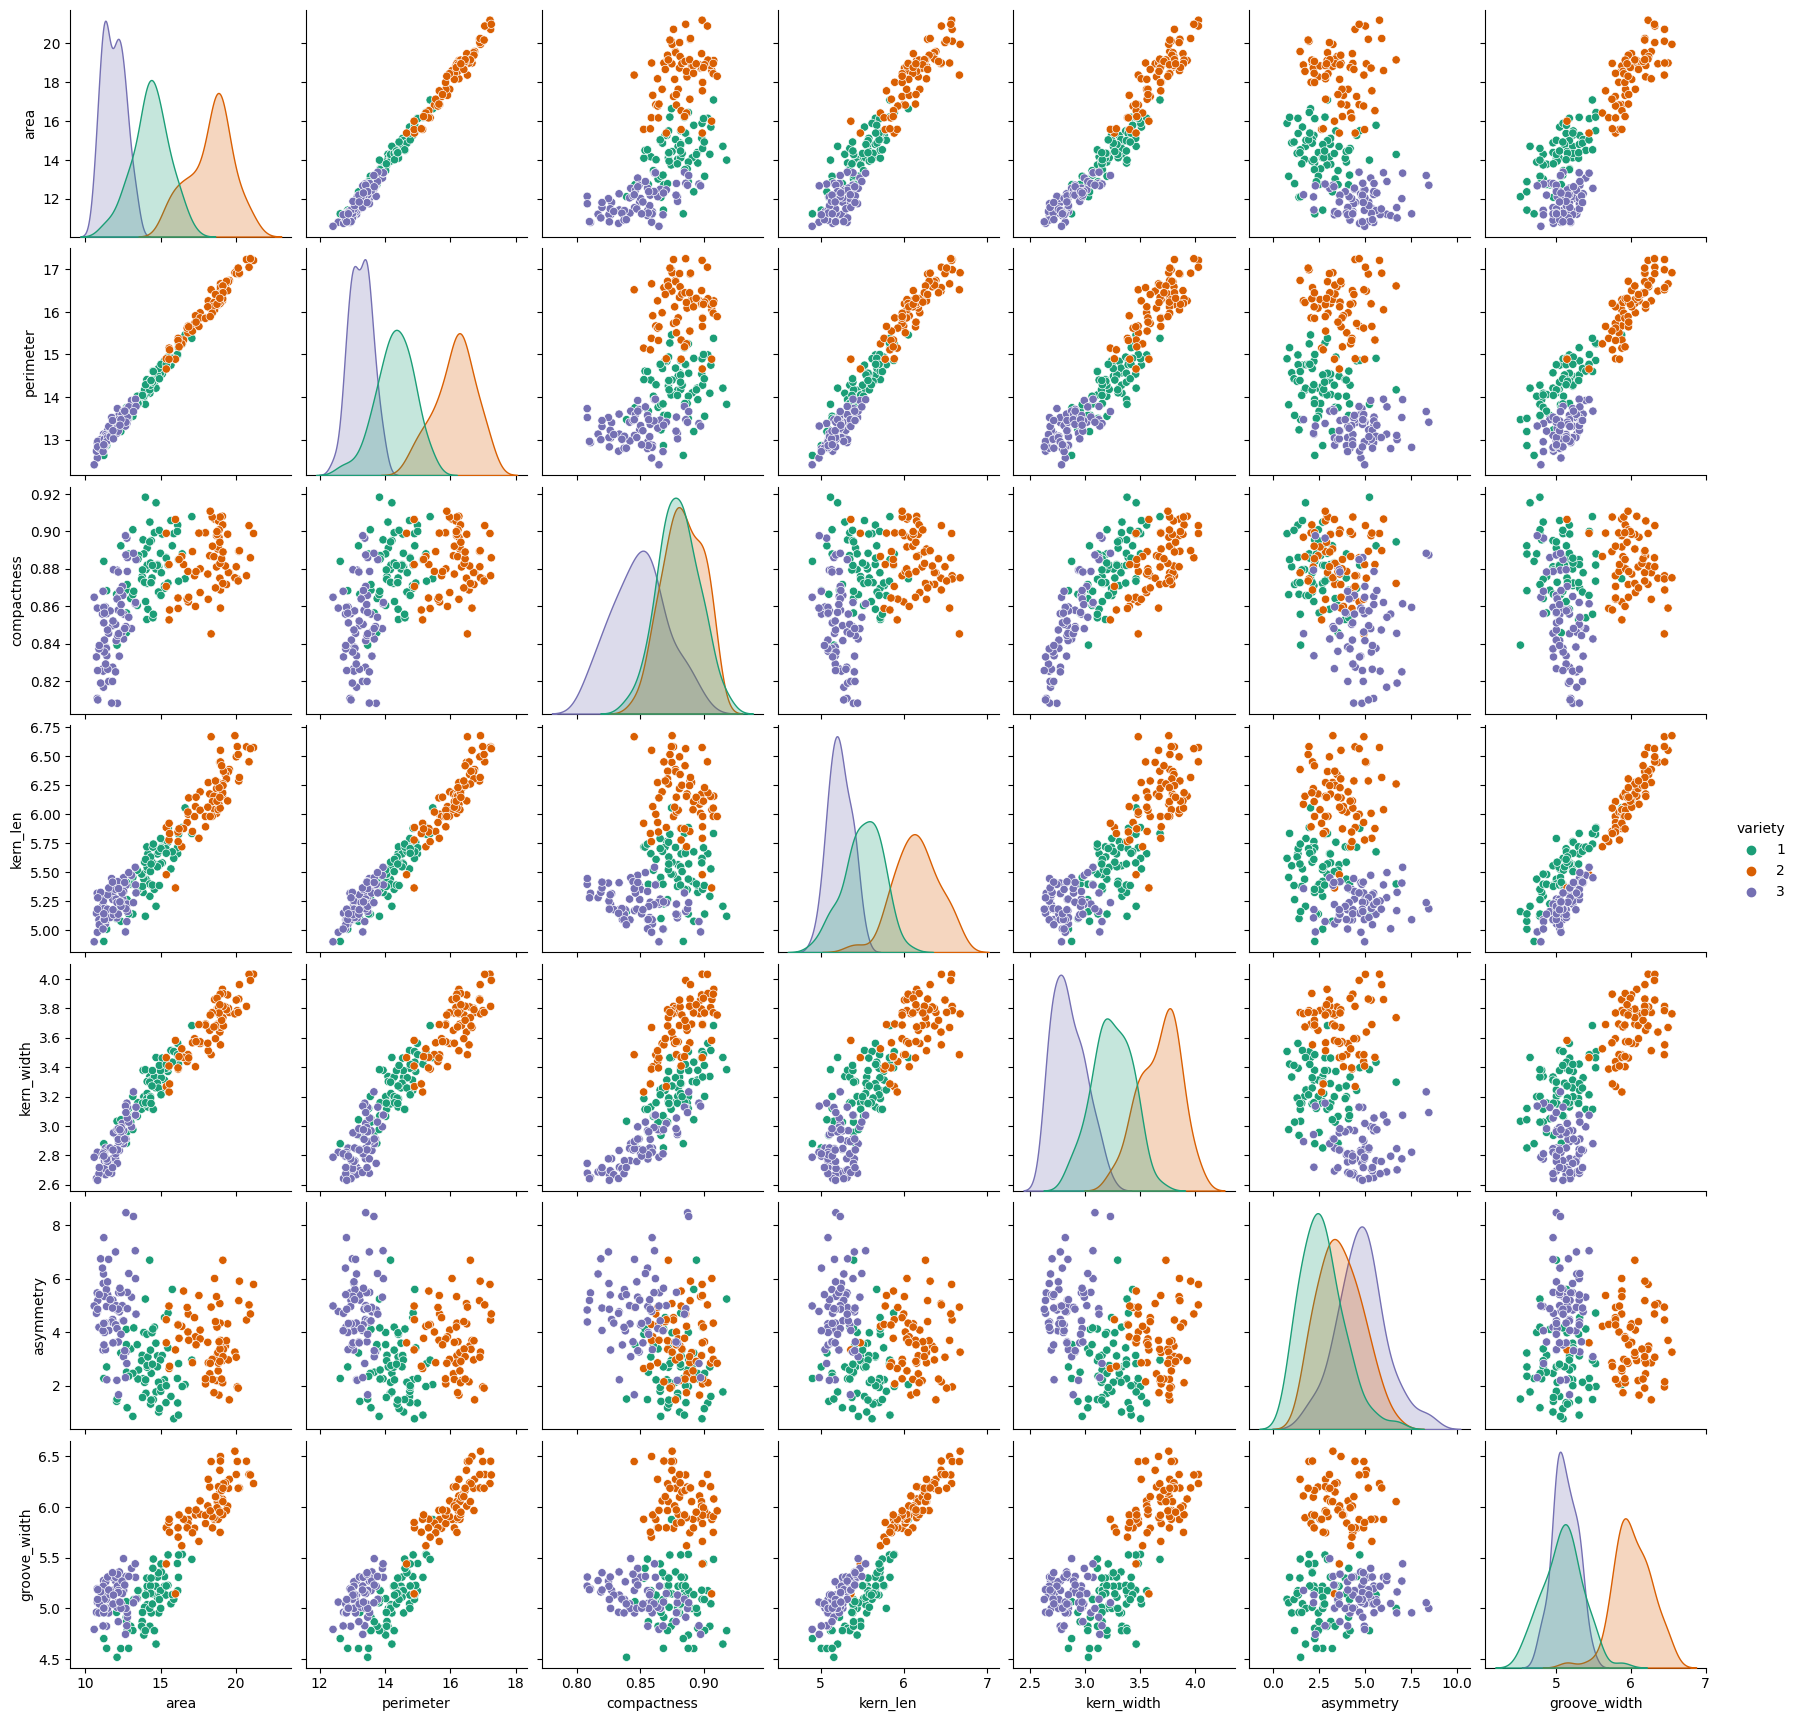

In [3]:
# Some fast EDA
sns.pairplot(seeds, hue='variety', palette='Dark2');

In [4]:
# Let's use ONLY kernel width and groove width to do our clustering.
# (YOU) make me an X and standard scale it!

X = seeds[['kern_width', 'groove_width']]
X_scaled = StandardScaler().fit_transform(X)

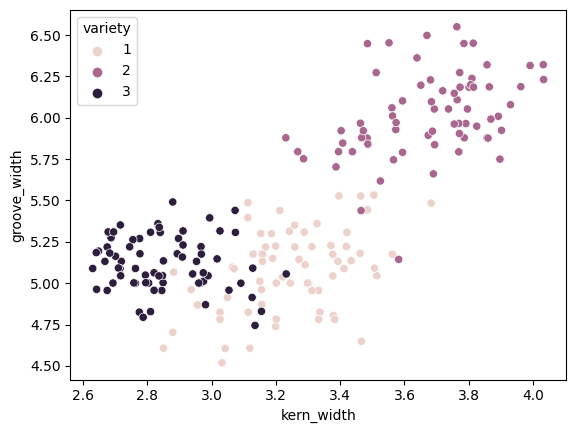

In [5]:
# Display the scatter plot between these two features

sns.scatterplot(data=seeds, x='kern_width', y='groove_width', hue ='variety');

# Fit a DBSCAN model
---

In [6]:
# Let's fit a DBSCAN with epsilon = 0.3 and n = 7

db = DBSCAN(eps=0.3, min_samples=7)
db.fit(X_scaled)

DBSCAN(eps=0.3, min_samples=7)

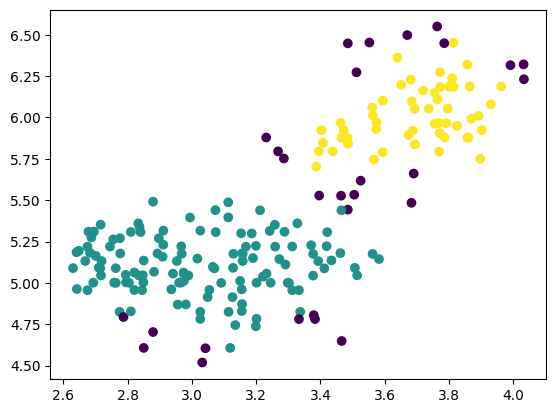

In [7]:
# Let's plot our clusters on the original data scale and color them in.

plt.scatter(X.kern_width, X.groove_width, c=db.labels_);

## Model Evaluation: Silhouette Score
---

Recall the formula for silhouette score:

### $s_i = \frac{b_i - a_i}{max\{a_i, b_i\}}$

Where:
- $a_i$ = Cohesion: Average distance of points within clusters
- $b_i$ = Separation: Average distance from point $x_i$ to all points in the next nearest cluster.

In the cell below, use the `silhouette_score` function from `scikit-learn` to evaluate our `DBSCAN` model.

In [8]:
# What's the silhouette score of our DBSCAN(0.3, 7) cluster?

silhouette_score(X_scaled, db.labels_)

0.4331166977120715

-0.4872295806218845

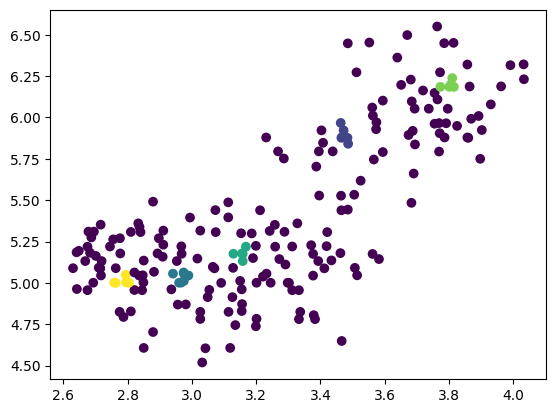

In [9]:
# Put everything in one cell here and rapidly iterate epsilon and cluster

db = DBSCAN(eps=0.1, min_samples=5)
db.fit(X_scaled)
plt.scatter(X.kern_width, X.groove_width, c=db.labels_)
silhouette_score(X_scaled, db.labels_)

In [10]:
# Painful, but you *could* brute force the params

e_vec = np.linspace(0.01, 1.5, 100)
n_vec = np.arange(1, 20)
res = []

for e in e_vec:
    for n in n_vec:
        cl = DBSCAN(eps=e, min_samples=n)
        cl.fit(X_scaled)
        lbls = pd.Series(cl.labels_)
        if lbls.nunique() <= 1:
            continue
            
        sil = silhouette_score(X_scaled, cl.labels_)
        res.append((e, n, sil))

In [11]:
df_res = pd.DataFrame(res, columns=['e', 'n', 'sil'])
df_res.head()

,e,n,sil
0,0.010000,1,0.025528
1,0.010000,2,-0.538707
2,0.025051,1,0.076518
3,0.025051,2,-0.589020
4,0.040101,1,0.106230


In [12]:
df_res.sort_values('sil', ascending=False)

,e,n,sil
408,0.536768,13,0.615489
425,0.581919,17,0.615489
420,0.566869,16,0.615489
421,0.566869,17,0.615489
422,0.566869,18,0.615489
...,...,...,...
12,0.070202,3,-0.514331
9,0.055152,3,-0.529392
5,0.040101,2,-0.537146
1,0.010000,2,-0.538707


0.6154893353164566

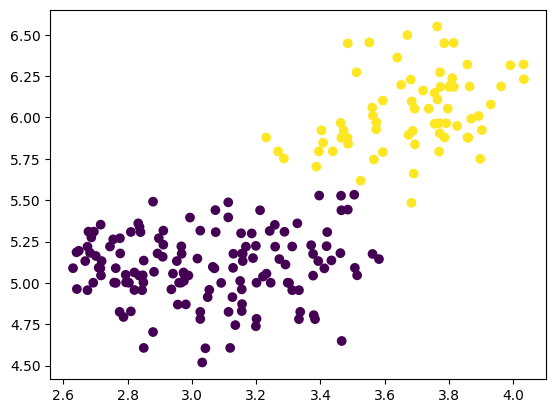

In [13]:
db = DBSCAN(eps=0.537, min_samples=13)
db.fit(X_scaled)
plt.scatter(X.kern_width, X.groove_width, c=db.labels_)
silhouette_score(X_scaled, db.labels_)

---

To the slides!

---

# Agglomerative (Hierarchical) Clustering
---
**Hierarchical clustering** is a technique in which we join or split successive clusters. We can plot such a models' **dendrogram** if we want, too!

In [14]:
# Let's fit an agglomerative clusterer with 3 clusters.
agglom = AgglomerativeClustering(3)
agglom.fit(X_scaled)

AgglomerativeClustering(n_clusters=3)

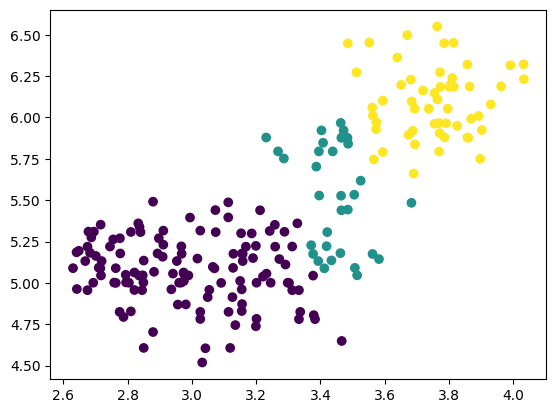

In [15]:
# Let's see it visually
plt.scatter(X.kern_width, X.groove_width, c=agglom.labels_);

In [16]:
# Silhouette?
silhouette_score(X_scaled, agglom.labels_)

0.4390897463455606

In [17]:
# TAKEN FROM SCIKIT-LEARN DOCS HERE!!
# https://scikit-learn.org/stable/auto_examples/cluster/plot_agglomerative_dendrogram.html

def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

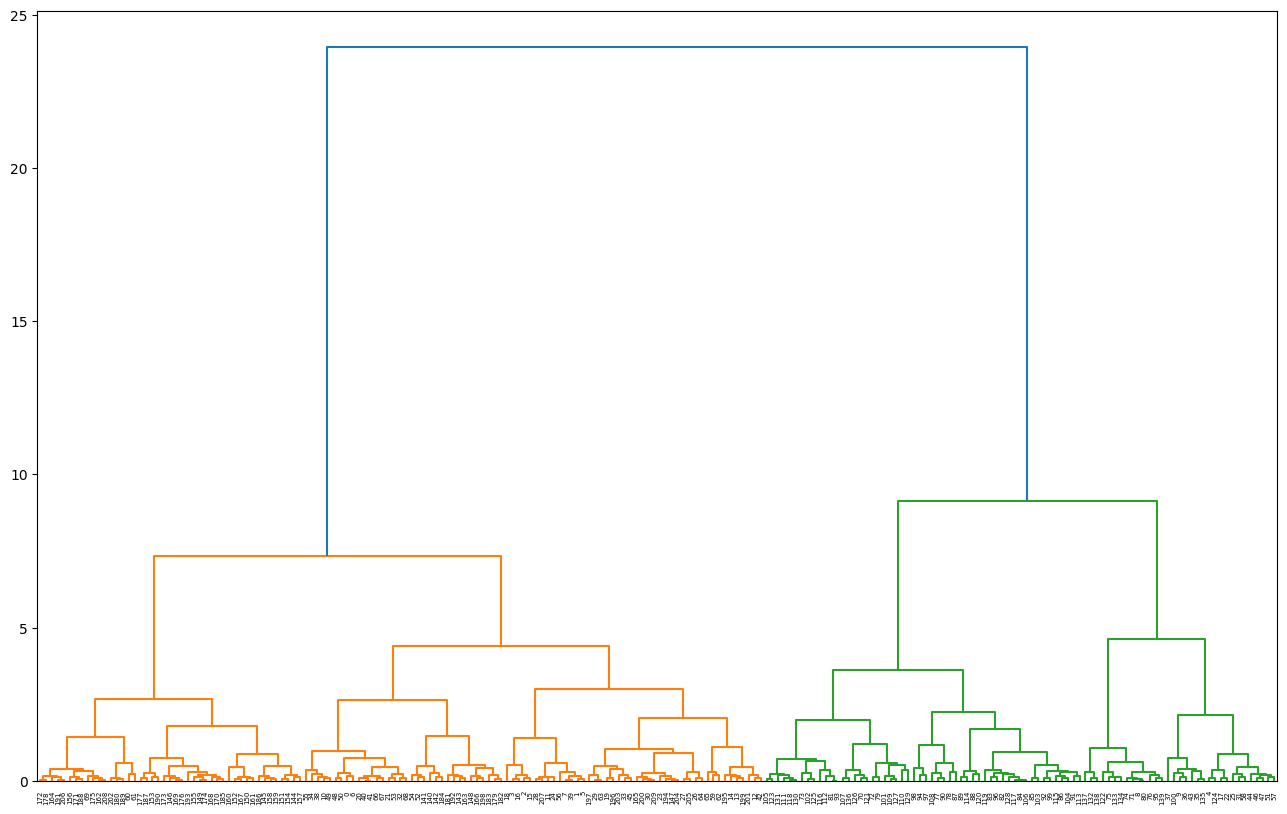

In [18]:
# These arguments are required to fit the whole tree. We can't plot the whole tree
# without computing it!
agglom = AgglomerativeClustering(n_clusters=None, distance_threshold=0)
agglom.fit(X_scaled)

plt.figure(figsize=(16, 10))
plot_dendrogram(agglom)

## DBSCAN conclusions
* DBSCAN is an interesting one in that it clusters based on the density of clusters...
* However, it comes at the cost of needing TWO (2!) tuning parameters.
* DBSCAN can also help us detect **outliers**.

## Agglomerative clustering conclusions
* Distance-based clustering algo that starts with every observation separate and successively joins clusters.
* Allows us to see the "path" of joins based similarity.
* Can plot nice **dendrograms**, although not always as useful as you'd think.

# Conclusions and Takeaways
---
Clustering is one of the two most common use cases for **unsupervised learning** (the other being dimensionality reduction). 

* It's used to segment your data into groups where members of one cluster are most similar to eachother than they are to observations in other groups.
* This process is totally independent of a $y$-variable! It only uses your $x$s.
* Almost all of these techniques rely on computing **distance metrics** between points, so **scaling** is important!
* There are many, many clustering algorithms out there and in sklearn! [Here are the ones we can enjoy via sklearn](https://scikit-learn.org/stable/modules/clustering.html#clustering).
* $k$-Means is probably the most well-known and therefore most commonly used.
* Although [k-medoids clustering](https://en.wikipedia.org/wiki/K-medoids) is a popular choice too, and it's not even contained in `scikit-learn`! It is very similar to k-means, though.